In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

df = pd.read_csv("customer_features.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (25000, 11)


,customer_id,customer_name,customer_segment,frequency,monetary_value,avg_order_value,recency_days,avg_discount_rate,avg_delivery_days,return_rate,purchase_frequency
0,CUST-000001,Donna Miller,Consumer,8,9469.55,1183.693750,7.0,0.121093,5.000000,0.125000,0.004477
1,CUST-000002,Joseph James,Consumer,10,18479.69,1847.969000,283.0,0.095423,5.857143,0.200000,0.005848
2,CUST-000003,Daniel Smith,Consumer,7,8268.66,1181.237143,210.0,0.086645,4.500000,0.142857,0.004152
3,CUST-000004,David Lopez,VIP,6,11092.52,1848.753333,55.0,0.192655,4.500000,0.166667,0.014599
4,CUST-000005,Dakota Davis,Consumer,8,10063.97,1257.996250,413.0,0.233239,5.125000,0.000000,0.004813


In [2]:
features = [
    "recency_days",
    "frequency",
    "monetary_value",
    "avg_order_value",
    "avg_discount_rate",
    "return_rate",
    "avg_delivery_days"
]

X = df[features].copy()

print("Missing values:")
print(X.isnull().sum())

print("\nSkewness:")
print(X.skew().sort_values(ascending=False))

print("\nCorrelation:")
display(X.corr().round(2))

Missing values:
recency_days         124
frequency              0
monetary_value         0
avg_order_value      124
avg_discount_rate    124
return_rate          124
avg_delivery_days    252
dtype: int64

Skewness:
return_rate          2.411808
recency_days         1.504923
avg_order_value      1.391092
avg_discount_rate    0.877687
monetary_value       0.855028
frequency            0.435294
avg_delivery_days    0.298553
dtype: float64

Correlation:


,recency_days,frequency,monetary_value,avg_order_value,avg_discount_rate,return_rate,avg_delivery_days
recency_days,1.00,-0.41,-0.30,-0.00,-0.07,0.01,0.01
frequency,-0.41,1.00,0.74,0.01,-0.01,-0.01,-0.01
monetary_value,-0.30,0.74,1.00,0.61,-0.01,0.01,-0.01
avg_order_value,-0.00,0.01,0.61,1.00,0.00,0.02,-0.00
avg_discount_rate,-0.07,-0.01,-0.01,0.00,1.00,-0.36,-0.01
return_rate,0.01,-0.01,0.01,0.02,-0.36,1.00,0.01
avg_delivery_days,0.01,-0.01,-0.01,-0.00,-0.01,0.01,1.00


In [3]:
log_features = [
    "recency_days",
    "frequency",
    "monetary_value",
    "avg_order_value"
]

# Make sure values are valid for log1p
for col in log_features:
    X[col] = X[col].clip(lower=0)

# Impute missing values using the median
imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=features,
    index=X.index
)

# Transform selected skewed features
X_transformed = X_imputed.copy()

for col in log_features:
    X_transformed[col] = np.log1p(X_transformed[col])

print("Skewness after transformation:")
print(X_transformed.skew().sort_values(ascending=False))

Skewness after transformation:
return_rate          2.419654
avg_discount_rate    0.881563
avg_delivery_days    0.301439
recency_days        -0.791209
frequency           -0.814063
avg_order_value     -0.904385
monetary_value      -4.117999
dtype: float64


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_transformed)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (25000, 7)


In [5]:
from sklearn.metrics import adjusted_rand_score

k_values = range(2, 9)
results = []
stability_results = {}

for k in k_values:
    labels_list = []

    for seed in [21, 42, 63, 84, 105]:
        model = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=10
        )
        labels = model.fit_predict(X_scaled)
        labels_list.append(labels)

    # Silhouette score from the first run
    silhouette = silhouette_score(
        X_scaled, labels_list[0],
        sample_size=min(10000, len(X_scaled)),
        random_state=42
    )

    # Compare cluster assignments across seeds
    ari_scores = [
        adjusted_rand_score(labels_list[i], labels_list[j])
        for i in range(len(labels_list))
        for j in range(i + 1, len(labels_list))
    ]

    results.append({
        "k": k,
        "silhouette_score": silhouette,
        "mean_stability_ARI": np.mean(ari_scores),
        "min_stability_ARI": np.min(ari_scores)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,k,silhouette_score,mean_stability_ARI,min_stability_ARI
0,2,0.2249,0.9924,0.9882
1,3,0.1926,0.9932,0.9881
2,4,0.1493,0.9111,0.8284
3,5,0.1569,0.7690,0.4779
4,6,0.1462,0.9527,0.9138
5,7,0.1470,0.9732,0.9605
6,8,0.1458,0.9616,0.9303


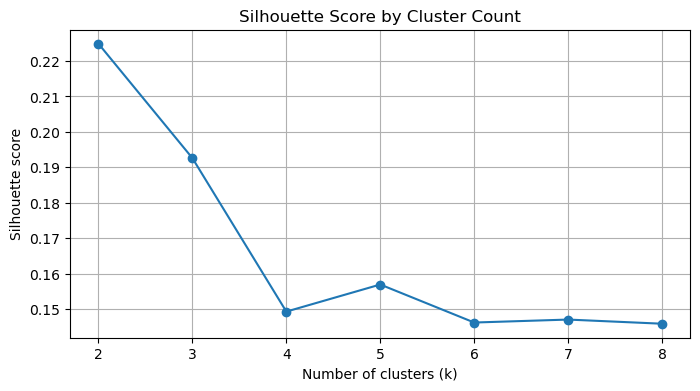

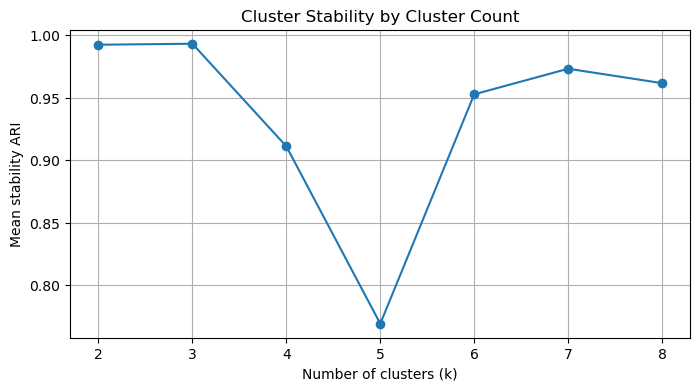

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(
    results_df["k"],
    results_df["silhouette_score"],
    marker="o"
)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score by Cluster Count")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(
    results_df["k"],
    results_df["mean_stability_ARI"],
    marker="o"
)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Mean stability ARI")
plt.title("Cluster Stability by Cluster Count")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [7]:
best_k = 4  # Change after reviewing silhouette, stability and profiles

final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

df["cluster"] = final_model.fit_predict(X_scaled)

profile = df.groupby("cluster").agg(
    customers=("customer_id", "nunique"),
    avg_recency_days=("recency_days", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary_value=("monetary_value", "mean"),
    avg_order_value=("avg_order_value", "mean"),
    avg_discount_rate=("avg_discount_rate", "mean"),
    avg_return_rate=("return_rate", "mean"),
    avg_delivery_days=("avg_delivery_days", "mean")
).round(2)

profile["customer_pct"] = (
    profile["customers"] / profile["customers"].sum() * 100
).round(2)

display(profile)

,customers,avg_recency_days,avg_frequency,avg_monetary_value,avg_order_value,avg_discount_rate,avg_return_rate,avg_delivery_days,customer_pct
cluster,,,,,,,,,
0,4232,356.83,4.85,6534.20,1366.94,0.11,0.30,4.61,16.93
1,3601,541.29,2.67,1842.05,751.30,0.17,0.01,4.55,14.40
2,10177,418.99,5.10,7745.46,1590.40,0.16,0.02,4.60,40.71
3,6990,53.53,6.82,9584.09,1418.61,0.18,0.05,4.51,27.96


In [8]:
cluster_labels = {
    # Replace these examples after inspecting your profile.
    # 0: "High-value frequent buyers",
    # 1: "Recent occasional buyers",
    # 2: "Lapsed repeat customers",
    # 3: "Moderate-value regular buyers"
}

df["cluster_label"] = df["cluster"].map(cluster_labels).fillna(
    df["cluster"].apply(lambda x: f"Cluster {x}")
)

display(
    df[["customer_id", "cluster", "cluster_label"]].head(10)
)

,customer_id,cluster,cluster_label
0,CUST-000001,3,Cluster 3
1,CUST-000002,0,Cluster 0
2,CUST-000003,0,Cluster 0
3,CUST-000004,3,Cluster 3
4,CUST-000005,2,Cluster 2
5,CUST-000006,2,Cluster 2
6,CUST-000007,0,Cluster 0
7,CUST-000008,3,Cluster 3
8,CUST-000009,0,Cluster 0
9,CUST-000010,2,Cluster 2


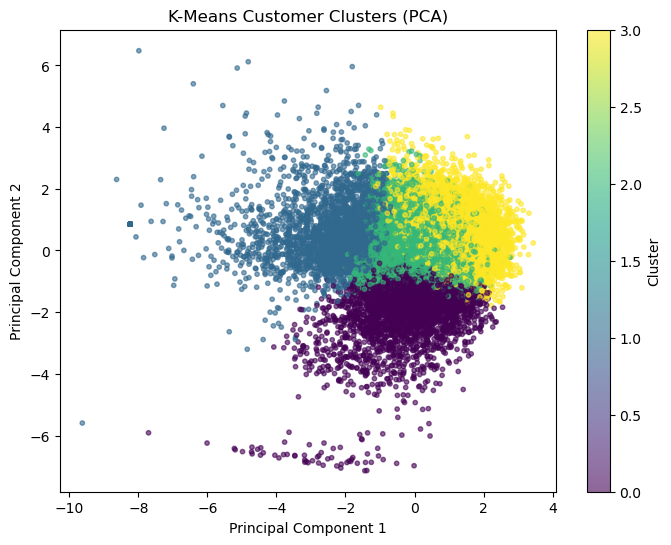

Variance explained by two components: 50.2 %


In [9]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["cluster"],
    s=10,
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Customer Clusters (PCA)")
plt.colorbar(scatter, label="Cluster")
plt.show()

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [10]:
df.to_csv("customer_kmeans_segments.csv", index=False)
profile.to_csv("kmeans_cluster_profile.csv")

print("K-Means clustering completed.")

K-Means clustering completed.
